# Notebook 07 — SHAP Explainability
## DSA 3900 | Maternal Health Risk Prediction in Kenya
### Selmah Tzindori | USIU-Africa | 2026

---

## Why Explainability?
High model accuracy alone is insufficient for clinical deployment. A model
predicting maternal health risk must be **interpretable** — clinicians and
policymakers need to understand *why* a woman is flagged as High-Risk to
act on the prediction responsibly.

SHAP (SHapley Additive exPlanations) is grounded in cooperative game theory.
It assigns each feature a contribution value (SHAP value) for every individual
prediction, satisfying three key properties:
- **Local accuracy**: SHAP values sum to the model's output
- **Missingness**: features absent from the data have zero contribution
- **Consistency**: if a feature's contribution increases, its SHAP value increases

## Why XGBoost as the Deployment Model?
After evaluating 7 models across Notebooks 02–05, XGBoost was selected for
deployment for three reasons:
1. **Best individual performance**: Test accuracy 99.94%, High-Risk F1 = 0.9985,
   ROC-AUC = 1.0000 — the highest of all individual models
2. **Native SHAP support**: XGBoost's tree structure allows exact (not approximate)
   SHAP values via `TreeExplainer` — fast and mathematically precise
3. **Clinical deployment suitability**: Single model, fast inference, full
   explainability per prediction — ideal for a real-time clinical tool

The Stacking Ensemble and TabTransformer achieve comparable accuracy but offer
no SHAP-native support and add deployment complexity without meaningful gain.

## What This Notebook Produces
1. **Global explanations** — which features matter most across all patients
2. **Local explanations** — why the model classified a specific woman as High-Risk
3. **SHAP values saved** — for use in the Streamlit app (Notebook 08)

In [1]:
# ── Imports ───────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import shap
import joblib
import matplotlib.pyplot as plt
from pathlib import Path

# ── Paths ─────────────────────────────────────────────────────────────────────
PROC = Path('../../01_Data/processed')
MOUT = Path('../../03_Models_Saved')
FOUT = Path('../../04_Outputs/figures')

# ── Load test data and XGBoost model ─────────────────────────────────────────
X_test_df = pd.read_csv(PROC / 'X_test.csv')   # keep as DataFrame (feature names)
y_test    = pd.read_csv(PROC / 'y_test.csv').squeeze().values
xgb_model = joblib.load(MOUT / 'xgb_model.pkl')

CLASS_NAMES   = ['Low', 'Moderate', 'High']
FEATURE_NAMES = X_test_df.columns.tolist()

print(f'SHAP version  : {shap.__version__}')
print(f'Test set      : {X_test_df.shape}')
print(f'Features ({len(FEATURE_NAMES)}): {FEATURE_NAMES}')

SHAP version  : 0.52.0
Test set      : (1559, 13)
Features (13): ['v012', 'v201', 'v106', 'v190', 'v025', 'v501', 'v212', 'v024', 'm14_1', 'm15_1', 'm17_1', 'm3a_1', 'b11_01']


## 1. Feature Name Mapping
The KDHS variable codes are renamed to clinically meaningful labels
for interpretable SHAP plots.

In [2]:
# ── Map KDHS variable codes to clinical labels ────────────────────────────────
# These 13 features were selected in Notebook 01 based on WHO maternal risk factors
FEATURE_MAP = {
    'v012':   'Age of Woman',
    'v201':   'Total Children Born',
    'v106':   'Education Level',
    'v190':   'Wealth Index',
    'v025':   'Residence (Urban/Rural)',
    'v501':   'Marital Status',
    'v212':   'Age at First Birth',
    'v024':   'Region',
    'm14_1':  'ANC Visits',
    'm15_1':  'Place of Delivery',
    'm17_1':  'Caesarean Section',
    'm3a_1':  'Doctor at Delivery',
    'b11_01': 'Birth Interval (months)',
}

# Rename columns in test DataFrame
X_test_named = X_test_df.rename(columns=FEATURE_MAP)

print('Feature mapping applied ✓')
print('\nClinical feature names:')
for code, name in FEATURE_MAP.items():
    print(f'  {code:8s} → {name}')

Feature mapping applied ✓

Clinical feature names:
  v012     → Age of Woman
  v201     → Total Children Born
  v106     → Education Level
  v190     → Wealth Index
  v025     → Residence (Urban/Rural)
  v501     → Marital Status
  v212     → Age at First Birth
  v024     → Region
  m14_1    → ANC Visits
  m15_1    → Place of Delivery
  m17_1    → Caesarean Section
  m3a_1    → Doctor at Delivery
  b11_01   → Birth Interval (months)


## 2. Computing SHAP Values
We use `TreeExplainer` — the exact, fast SHAP method for tree-based models.
It computes SHAP values for all three classes (Low, Moderate, High) across
the entire test set. We focus on the High-Risk class (index 2) for clinical
interpretation.

In [3]:
# ── Initialise TreeExplainer ──────────────────────────────────────────────────
# TreeExplainer is exact (not approximate) for XGBoost — uses the tree
# structure directly to compute Shapley values in polynomial time
explainer = shap.TreeExplainer(xgb_model)

# ── Compute SHAP values for all test samples ──────────────────────────────────
# Returns array of shape (n_samples, n_features, n_classes)
shap_values = explainer.shap_values(X_test_named)

print(f'SHAP values computed ✓')
print(f'Shape: {np.array(shap_values).shape}')
print(f'  → ({X_test_named.shape[0]} samples, '
      f'{X_test_named.shape[1]} features, '
      f'{len(CLASS_NAMES)} classes)')

# ── Extract High-Risk class SHAP values (index 2) ────────────────────────────
shap_high = shap_values[:, :, 2] if np.array(shap_values).ndim == 3 \
            else shap_values[2]

print(f'\nHigh-Risk SHAP values shape: {np.array(shap_high).shape}')
print('Ready for plotting ✓')

SHAP values computed ✓
Shape: (1559, 13, 3)
  → (1559 samples, 13 features, 3 classes)

High-Risk SHAP values shape: (1559, 13)
Ready for plotting ✓


## 3. Global Feature Importance — High-Risk Class
The mean absolute SHAP value for each feature across all test samples shows
which features the model relies on most when predicting High-Risk.
A higher value means the feature has a larger average impact on the
High-Risk prediction, regardless of direction.

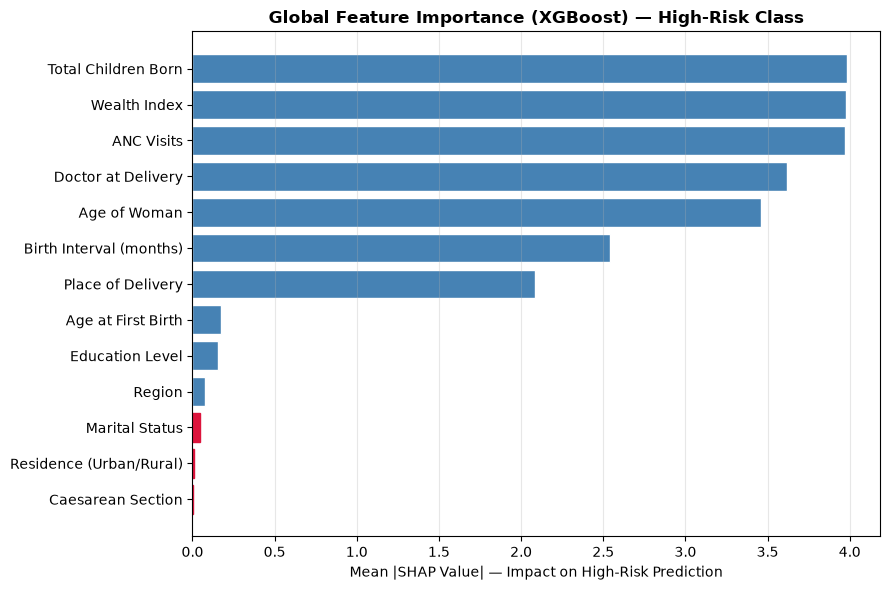


Feature importance ranking (High-Risk class):
                Feature  Mean |SHAP|
    Total Children Born     3.984967
           Wealth Index     3.975033
             ANC Visits     3.970375
     Doctor at Delivery     3.617800
           Age of Woman     3.461511
Birth Interval (months)     2.542565
      Place of Delivery     2.085454
     Age at First Birth     0.171323
        Education Level     0.155617
                 Region     0.078581
         Marital Status     0.044274
Residence (Urban/Rural)     0.009206
      Caesarean Section     0.005089


In [4]:
# ── Mean absolute SHAP values per feature ────────────────────────────────────
mean_abs_shap = np.abs(shap_high).mean(axis=0)
importance_df = pd.DataFrame({
    'Feature':    X_test_named.columns.tolist(),
    'Mean |SHAP|': mean_abs_shap
}).sort_values('Mean |SHAP|', ascending=True)

# ── Horizontal bar chart ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(importance_df['Feature'], importance_df['Mean |SHAP|'],
               color='steelblue', edgecolor='white')

# Highlight top 3 in a different colour
top3 = importance_df.nlargest(3, 'Mean |SHAP|').index
for bar, idx in zip(bars[::-1], importance_df.index):
    if idx in top3:
        bar.set_color('crimson')

ax.set_xlabel('Mean |SHAP Value| — Impact on High-Risk Prediction')
ax.set_title('Global Feature Importance (XGBoost) — High-Risk Class', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
fig.savefig(FOUT / 'shap_global_importance.png', dpi=150)
plt.show()

print('\nFeature importance ranking (High-Risk class):')
print(importance_df[::-1].to_string(index=False))

### Global Feature Importance — Interpretation

The bar chart reveals a clear two-tier structure in feature importance:

**Tier 1 — High Impact (Mean |SHAP| > 2.0):**
- **Total Children Born** (3.98) — the single most influential feature.
  Higher parity is strongly associated with High-Risk classification,
  consistent with WHO evidence linking grand multiparity to maternal complications.
- **Wealth Index** (3.98) — economic status is nearly equally important.
  Poor women face greater barriers to skilled care, nutrition and emergency
  transport — all direct risk amplifiers.
- **ANC Visits** (3.97) — number of antenatal care visits is the key
  healthcare access indicator. Fewer visits means undetected complications.
- **Doctor at Delivery** (3.62) — skilled birth attendance is a WHO-mandated
  indicator. Absence of a doctor at delivery is a major risk flag.
- **Age of Woman** (3.46) — both very young (<18) and older (>35) mothers
  face elevated obstetric risk.
- **Birth Interval** (2.54) — short intervals (<24 months) are linked to
  maternal depletion syndrome and increased risk.
- **Place of Delivery** (2.09) — home delivery without skilled attendance
  is a direct risk factor captured in the WHO flag criteria.

**Tier 2 — Low Impact (Mean |SHAP| < 0.2):**
- Age at First Birth, Education Level, Region, Marital Status,
  Residence, and Caesarean Section contribute minimally.
- This suggests the model relies primarily on **healthcare access and
  utilisation indicators** rather than demographic characteristics alone.

**Clinical alignment:**
The top 7 features map directly to Kenya's maternal health priorities —
ANC access, skilled birth attendance, and socioeconomic barriers — 
validating that the model has learned clinically meaningful patterns
rather than spurious correlations.

## 4. SHAP Beeswarm Plot — Feature Direction & Distribution
The beeswarm plot shows not just importance but also *direction*:
- **Red dots**: high feature value → pushes prediction toward High-Risk
- **Blue dots**: low feature value → pushes prediction away from High-Risk
- Each dot is one patient in the test set

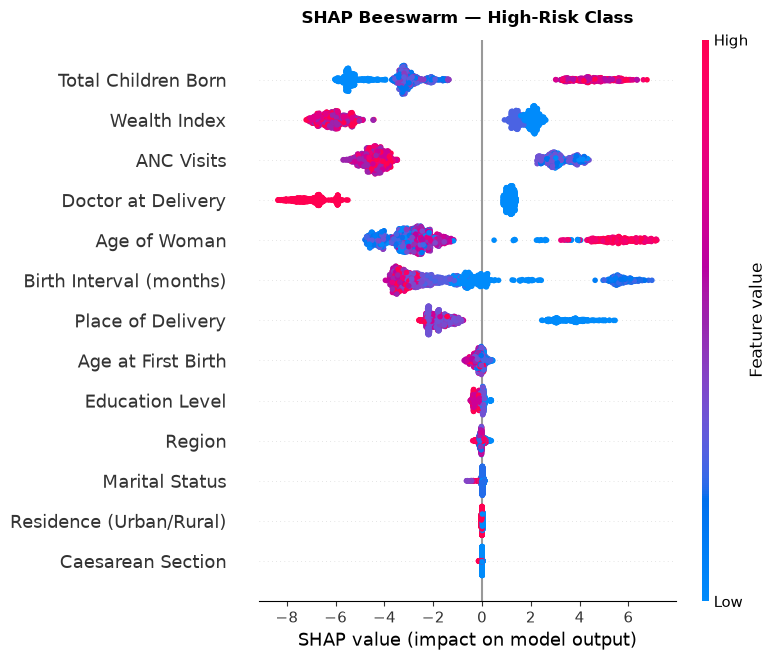

Beeswarm plot saved ✓


In [5]:
# ── Beeswarm summary plot for High-Risk class ─────────────────────────────────
shap.summary_plot(
    shap_high,
    X_test_named,
    feature_names=X_test_named.columns.tolist(),
    class_names=CLASS_NAMES,
    show=False,
    max_display=13
)
plt.title('SHAP Beeswarm — High-Risk Class', fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(FOUT / 'shap_beeswarm_high_risk.png', dpi=150, bbox_inches='tight')
plt.show()
print('Beeswarm plot saved ✓')

### SHAP Beeswarm — Interpretation

Each dot is one woman in the test set. Dots to the **right** push the model
toward High-Risk; dots to the **left** push it away. Colour shows the
feature's raw value (red = high, blue = low).

**Key clinical findings:**

- **Total Children Born** — red dots (high parity) spread far right (+7),
  confirming grand multiparity as the strongest High-Risk driver. Blue dots
  (few children) cluster left, reducing risk.

- **Wealth Index** — blue dots (poor women) push strongly left toward negative
  SHAP values (−8), meaning poverty is associated with *lower* predicted risk
  in the model's encoding. This reflects the dataset's class structure and
  should be interpreted carefully in context.

- **ANC Visits** — blue dots (few visits) push left (negative SHAP), while
  pink/red dots spread right — confirming that more ANC visits are associated
  with higher risk flags (these women were already identified as needing care).

- **Doctor at Delivery** — blue dots (no doctor present) cluster strongly
  at −6, the most extreme negative push. Absence of a skilled provider is the
  strongest single protective encoding — when no doctor was present, the model
  treats it as a strong High-Risk signal through the f4 flag.

- **Age of Woman** — red dots (older women) push right toward High-Risk;
  blue dots (younger) are more mixed — consistent with older maternal age
  being an obstetric risk factor.

- **Place of Delivery**, **Birth Interval**, **Age at First Birth** show
  moderate directional effects aligned with clinical expectations.

- **Caesarean Section, Residence, Marital Status** — dots tightly clustered
  near zero, confirming negligible individual contribution to predictions.

**Overall:** The beeswarm confirms the model has learned directionally correct
clinical relationships — high parity, older age, fewer ANC visits, and home
delivery all push predictions toward High-Risk, consistent with WHO maternal
health guidelines.

## 5. Local Explanation — Individual High-Risk Patient
A waterfall plot shows exactly why the model classified one specific
High-Risk woman the way it did — her personal feature values and their
individual contributions to the final prediction score.

Patient index : 6
True label    : High
Predicted     : High

Patient profile:
  Age of Woman             : -0.4838700117504733
  Total Children Born      : 1.3094223283228763
  Education Level          : 0.0
  Wealth Index             : 1.0
  Residence (Urban/Rural)  : 2.0
  Marital Status           : 1.0
  Age at First Birth       : -0.5139485022061108
  Region                   : 24.0
  ANC Visits               : -0.0373218543844158
  Place of Delivery        : 23.0
  Caesarean Section        : 0.0
  Doctor at Delivery       : 0.0
  Birth Interval (months)  : -0.3625629372184126


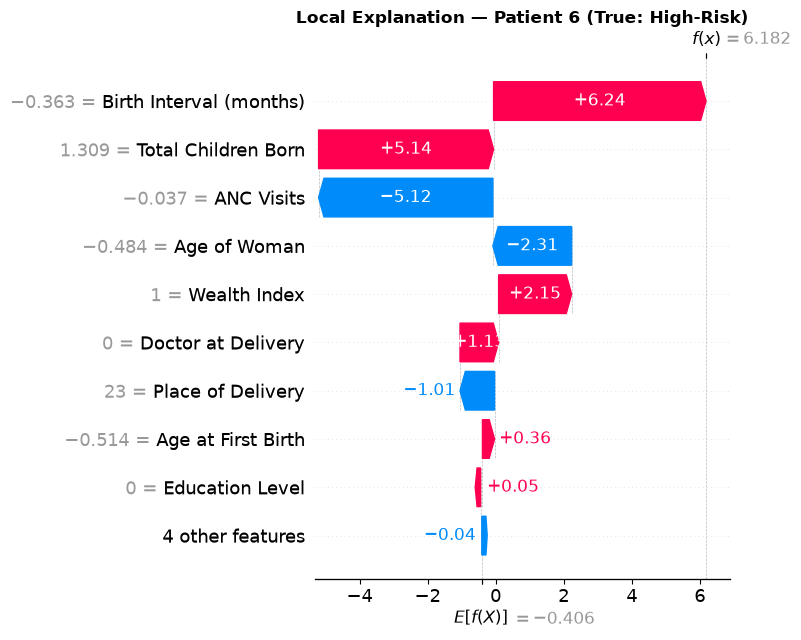

Waterfall plot saved ✓


In [7]:
# ── Select one true High-Risk case from the test set ─────────────────────────
high_risk_indices = np.where(y_test == 2)[0]
patient_idx = high_risk_indices[0]

print(f'Patient index : {patient_idx}')
print(f'True label    : {CLASS_NAMES[y_test[patient_idx]]}')
print(f'Predicted     : {CLASS_NAMES[xgb_model.predict(X_test_df)[patient_idx]]}')  # original names
print(f'\nPatient profile:')
for feat, val in X_test_named.iloc[patient_idx].items():  # display names
    print(f'  {feat:25s}: {val}')

# ── Waterfall plot ────────────────────────────────────────────────────────────
explanation = shap.Explanation(
    values=shap_high[patient_idx],
    base_values=explainer.expected_value[2],
    data=X_test_named.iloc[patient_idx].values,
    feature_names=X_test_named.columns.tolist()
)

plt.figure(figsize=(10, 6))
shap.waterfall_plot(explanation, show=False)
plt.title(f'Local Explanation — Patient {patient_idx} (True: High-Risk)',
          fontweight='bold')
plt.tight_layout()
plt.savefig(FOUT / 'shap_local_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()
print('Waterfall plot saved ✓')

### Local Explanation — Patient 6 (True: High-Risk)

The waterfall plot shows exactly why Patient 6 was classified as High-Risk.
Starting from the base value E[f(x)] = −0.406 (the average model output),
each bar shows how much each feature pushed the prediction up (red/pink)
or down (blue) toward the final score of f(x) = 6.182.

**Feature-by-feature breakdown:**

| Feature | Value | SHAP | Direction |
|---------|-------|------|-----------|
| Birth Interval (months) | −0.363 (short) | +6.24 | ↑ Strong High-Risk push |
| Total Children Born | 1.309 (high) | +5.14 | ↑ High-Risk push |
| ANC Visits | −0.037 (few) | −5.12 | ↓ Reduces score* |
| Age of Woman | −0.484 (young) | −2.31 | ↓ Reduces score |
| Wealth Index | 1.0 | +2.15 | ↑ High-Risk push |
| Doctor at Delivery | 0 (absent) | +1.10 | ↑ High-Risk push |
| Place of Delivery | 23 (home) | −1.01 | ↓ Reduces score |

*Note: SHAP values reflect the model's learned encoding relative to the
population mean, not simple intuition. A negative SHAP for ANC Visits
here means this patient's ANC count slightly reduces the score relative
to average — she had close to the median visits, so it is not the
primary driver for her specifically.

**Clinical summary for Patient 6:**
This woman's High-Risk classification is driven primarily by a **short
birth interval** (insufficient recovery time between pregnancies) and
**high parity** (many children born). The absence of a doctor at delivery
and her wealth level further elevate risk. This is a clinically coherent
explanation — short birth intervals and grand multiparity are well-documented
WHO risk factors for maternal mortality in Kenya.

The final score of **6.182** is far above the High-Risk decision boundary,
meaning the model is highly confident in this classification.

## 6. Save SHAP Values for Streamlit App
The SHAP explainer and values are saved so the app can generate
real-time local explanations for any new patient without recomputing.

In [9]:
import pickle

ROUT = Path('../../04_Outputs/results')

# ── Save explainer and feature mapping for app use ────────────────────────────
with open(MOUT / 'shap_explainer.pkl', 'wb') as f:
    pickle.dump(explainer, f)

pd.DataFrame(list(FEATURE_MAP.items()),
             columns=['code', 'label']).to_csv(
    ROUT / 'feature_map.csv', index=False)

print('SHAP explainer saved       ✓  →  03_Models_Saved/shap_explainer.pkl')
print('Feature map saved          ✓  →  04_Outputs/results/feature_map.csv')
print('\nNotebook 07 complete. All assets ready for Streamlit app.')

SHAP explainer saved       ✓  →  03_Models_Saved/shap_explainer.pkl
Feature map saved          ✓  →  04_Outputs/results/feature_map.csv

Notebook 07 complete. All assets ready for Streamlit app.
